In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("../Data/IPL_Matches.csv")

print("Shape of dataset:", df.shape)
print("\nColumns:\n", df.columns)
df.head()

Shape of dataset: (950, 20)

Columns:
 Index(['ID', 'City', 'Date', 'Season', 'MatchNumber', 'Team1', 'Team2',
       'Venue', 'TossWinner', 'TossDecision', 'SuperOver', 'WinningTeam',
       'WonBy', 'Margin', 'method', 'Player_of_Match', 'Team1Players',
       'Team2Players', 'Umpire1', 'Umpire2'],
      dtype='object')


,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,N,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,N,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,N,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,N,Gujarat Titans,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,N,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan


In [5]:
# Basic structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 950 entries, 0 to 949
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               950 non-null    int64  
 1   City             899 non-null    object 
 2   Date             950 non-null    object 
 3   Season           950 non-null    object 
 4   MatchNumber      950 non-null    object 
 5   Team1            950 non-null    object 
 6   Team2            950 non-null    object 
 7   Venue            950 non-null    object 
 8   TossWinner       950 non-null    object 
 9   TossDecision     950 non-null    object 
 10  SuperOver        946 non-null    object 
 11  WinningTeam      946 non-null    object 
 12  WonBy            950 non-null    object 
 13  Margin           932 non-null    float64
 14  method           19 non-null     object 
 15  Player_of_Match  946 non-null    object 
 16  Team1Players     950 non-null    object 
 17  Team2Players    

In [7]:
# Null values in each column
df.isnull().sum()

ID                   0
City                51
Date                 0
Season               0
MatchNumber          0
Team1                0
Team2                0
Venue                0
TossWinner           0
TossDecision         0
SuperOver            4
WinningTeam          4
WonBy                0
Margin              18
method             931
Player_of_Match      4
Team1Players         0
Team2Players         0
Umpire1              0
Umpire2              0
dtype: int64

In [9]:
# Drop unnecessary columns
df.drop(['ID', 'Team1Players', 'Team2Players', 'Umpire1', 'Umpire2'], axis=1, inplace=True)

In [11]:
# Drop unnecessary columns
df.drop(['method'], axis=1, inplace=True)
df = df.loc[df['WinningTeam'].notna()].reset_index(drop=True)

In [13]:
# Convert date to datetime
df['Date'] = pd.to_datetime(df['Date'])

In [15]:
# Fill missing values
df['Player_of_Match'] = df['Player_of_Match'].fillna('Unknown')
df['City'] = df['City'].fillna(0.0)
df['Margin'] = df['Margin'].fillna(0.0)
df['SuperOver'] = df['SuperOver'].fillna('No')

In [17]:
df.rename(columns={'WinningTeam': 'Winner'}, inplace=True)
df.drop_duplicates(inplace=True)

In [19]:
# Again cheak for Null value 
df.isnull().sum()

City               0
Date               0
Season             0
MatchNumber        0
Team1              0
Team2              0
Venue              0
TossWinner         0
TossDecision       0
SuperOver          0
Winner             0
WonBy              0
Margin             0
Player_of_Match    0
dtype: int64

In [21]:
# Save filter data in new csv
df.to_csv('../Data/FilterDataIPL.csv', index=False)

In [23]:
# EDA
print(f"Total matches: {df.shape[0]}\n")
print(f"Total seasons: {df['Season'].nunique()}\n")
print(f"Total unique teams :{df['Team1'].unique()}\n")
print(f"Top hosting cities :{df['City'].value_counts().head()}\n")
print(f'Top winning teams :{df['Winner'].value_counts().head()}\n')
# value_counts() is count each elements ans sort them in desending order

Total matches: 946

Total seasons: 15

Total unique teams :['Rajasthan Royals' 'Royal Challengers Bangalore' 'Sunrisers Hyderabad'
 'Delhi Capitals' 'Chennai Super Kings' 'Gujarat Titans'
 'Lucknow Super Giants' 'Kolkata Knight Riders' 'Punjab Kings'
 'Mumbai Indians' 'Kings XI Punjab' 'Delhi Daredevils'
 'Rising Pune Supergiant' 'Gujarat Lions' 'Rising Pune Supergiants'
 'Pune Warriors' 'Deccan Chargers' 'Kochi Tuskers Kerala']

Top hosting cities :City
Mumbai       159
Kolkata       79
Delhi         77
Chennai       67
Hyderabad     64
Name: count, dtype: int64

Top winning teams :Winner
Mumbai Indians                 131
Chennai Super Kings            121
Kolkata Knight Riders          114
Royal Challengers Bangalore    109
Rajasthan Royals                96
Name: count, dtype: int64



In [25]:
print("Most Winning team :",df['Winner'].value_counts().head())
print("\nTop 5 players of the match :",df['Player_of_Match'].value_counts().head())
print("\nMost toss-winning team :",df['TossWinner'].value_counts().head())
print("\nMost mvp players :",df['Player_of_Match'].value_counts().head())

Most Winning team : Winner
Mumbai Indians                 131
Chennai Super Kings            121
Kolkata Knight Riders          114
Royal Challengers Bangalore    109
Rajasthan Royals                96
Name: count, dtype: int64

Top 5 players of the match : Player_of_Match
AB de Villiers    25
CH Gayle          22
DA Warner         18
RG Sharma         18
MS Dhoni          17
Name: count, dtype: int64

Most toss-winning team : TossWinner
Mumbai Indians                 123
Kolkata Knight Riders          114
Chennai Super Kings            109
Royal Challengers Bangalore    104
Rajasthan Royals                97
Name: count, dtype: int64

Most mvp players : Player_of_Match
AB de Villiers    25
CH Gayle          22
DA Warner         18
RG Sharma         18
MS Dhoni          17
Name: count, dtype: int64


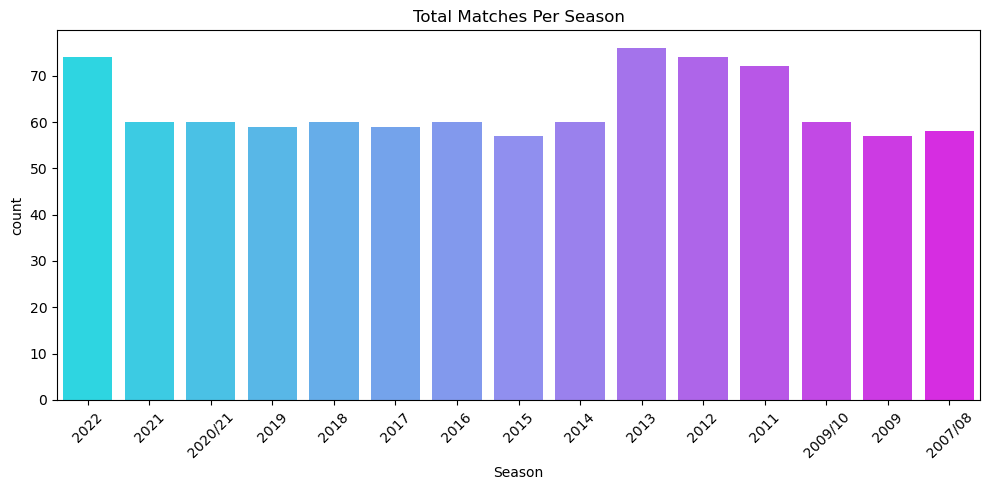

In [23]:
# 1. Matches per season
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Season',hue='Season', palette='cool')
plt.title('Total Matches Per Season')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../OutputPlots/Matches_per_season.png', bbox_inches='tight')
plt.show()

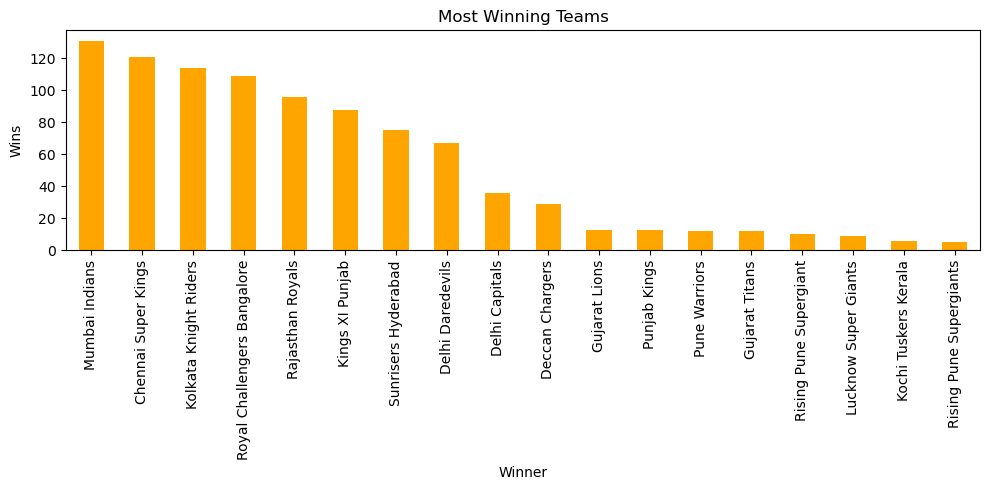

In [25]:
# 2. Most winning teams
plt.figure(figsize=(10,5))
df['Winner'].value_counts().plot(kind='bar', color='orange')
# OR
#sns.countplot(x="Winner",data=df,palette='cool')

plt.title('Most Winning Teams')
plt.ylabel('Wins')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('../OutputPlots/Most_winning_teams.png', bbox_inches='tight')
plt.show()

## Advanced Insights 

In [32]:
# What is persentage of winning match if team win toss??
same_winner=df[df['TossWinner']==df['Winner']]
total_matches=df.shape[0]
same_winner_percent=(same_winner.shape[0]/total_matches)*100;
print(f"Toss winner also won the match in {same_winner_percent:.2f}% of the matches.")

Toss winner also won the match in 51.69% of the matches.


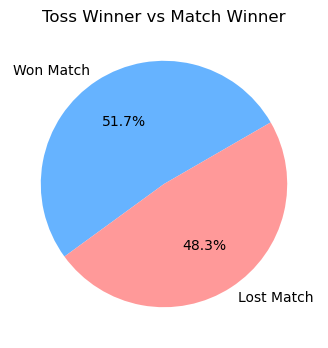

In [46]:
plt.figure(figsize=(5, 4))
labels = ['Won Match', 'Lost Match']
values = [same_winner.shape[0], total_matches - same_winner.shape[0]]
plt.pie(values, labels=labels, autopct='%1.1f%%', startangle=30, colors=['#66b3ff','#ff9999'])
plt.title('Toss Winner vs Match Winner')
plt.savefig('../OutputPlots/TossWin_vs_MatchWin.png', bbox_inches='tight')
plt.show()

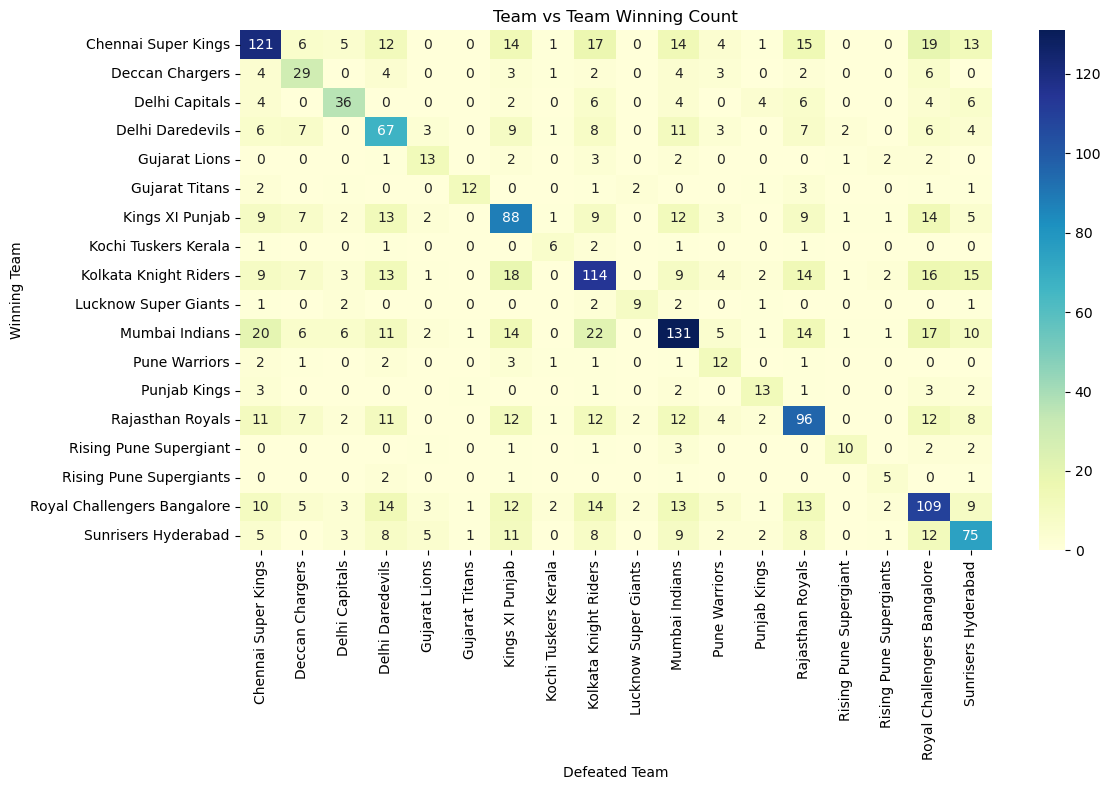

In [48]:
# Crosstab create frequancy of that How many times Winner with Trem1 and Team2 (i.e. COunt of winning team in front of team1 and team2)
head_to_head = pd.crosstab(df['Winner'], df['Team1']) + pd.crosstab(df['Winner'], df['Team2'])
# Fill missing values with 0
head_to_head = head_to_head.fillna(0).astype(int)

# Plot Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(head_to_head, annot=True, cmap="YlGnBu", fmt="d")
plt.title("Team vs Team Winning Count")
plt.xlabel("Defeated Team")
plt.ylabel("Winning Team")
plt.tight_layout()
plt.savefig('../OutputPlots/Team_vs_Team_winning.png', bbox_inches='tight')
plt.show()

In [50]:
pd.crosstab(df['Winner'], df['Team1'])+pd.crosstab(df['Winner'], df['Team2'])

Team1,Chennai Super Kings,Deccan Chargers,Delhi Capitals,Delhi Daredevils,Gujarat Lions,Gujarat Titans,Kings XI Punjab,Kochi Tuskers Kerala,Kolkata Knight Riders,Lucknow Super Giants,Mumbai Indians,Pune Warriors,Punjab Kings,Rajasthan Royals,Rising Pune Supergiant,Rising Pune Supergiants,Royal Challengers Bangalore,Sunrisers Hyderabad
Winner,,,,,,,,,,,,,,,,,,
Chennai Super Kings,121,6,5,12,0,0,14,1,17,0,14,4,1,15,0,0,19,13
Deccan Chargers,4,29,0,4,0,0,3,1,2,0,4,3,0,2,0,0,6,0
Delhi Capitals,4,0,36,0,0,0,2,0,6,0,4,0,4,6,0,0,4,6
Delhi Daredevils,6,7,0,67,3,0,9,1,8,0,11,3,0,7,2,0,6,4
Gujarat Lions,0,0,0,1,13,0,2,0,3,0,2,0,0,0,1,2,2,0
Gujarat Titans,2,0,1,0,0,12,0,0,1,2,0,0,1,3,0,0,1,1
Kings XI Punjab,9,7,2,13,2,0,88,1,9,0,12,3,0,9,1,1,14,5
Kochi Tuskers Kerala,1,0,0,1,0,0,0,6,2,0,1,0,0,1,0,0,0,0
Kolkata Knight Riders,9,7,3,13,1,0,18,0,114,0,9,4,2,14,1,2,16,15


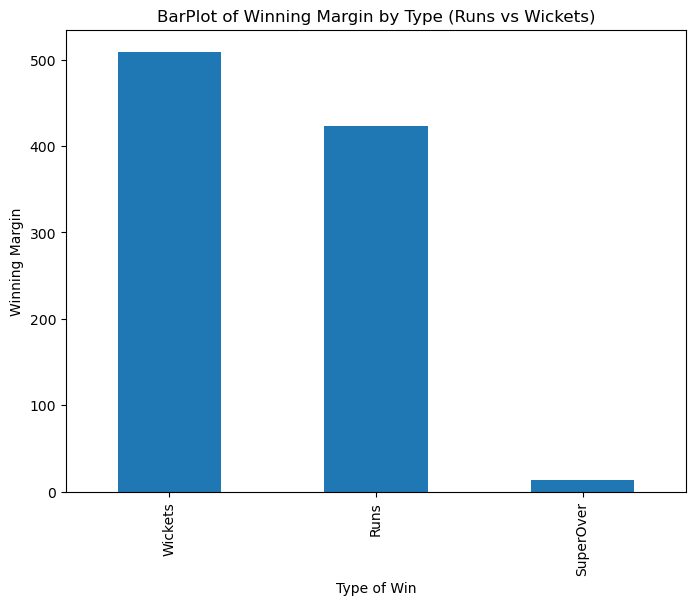

In [64]:
plt.figure(figsize=(8, 6))
df['WonBy'].value_counts().plot(kind='bar')
plt.title("BarPlot of Winning Margin by Type (Runs vs Wickets)")
plt.xlabel("Type of Win")
plt.ylabel("Winning Margin")
plt.savefig('../OutputPlots/WinningMargin.png', bbox_inches='tight')
plt.show()

In [72]:
grouped_df = df.groupby(['Season', 'Winner']).size().reset_index(name='Wins')

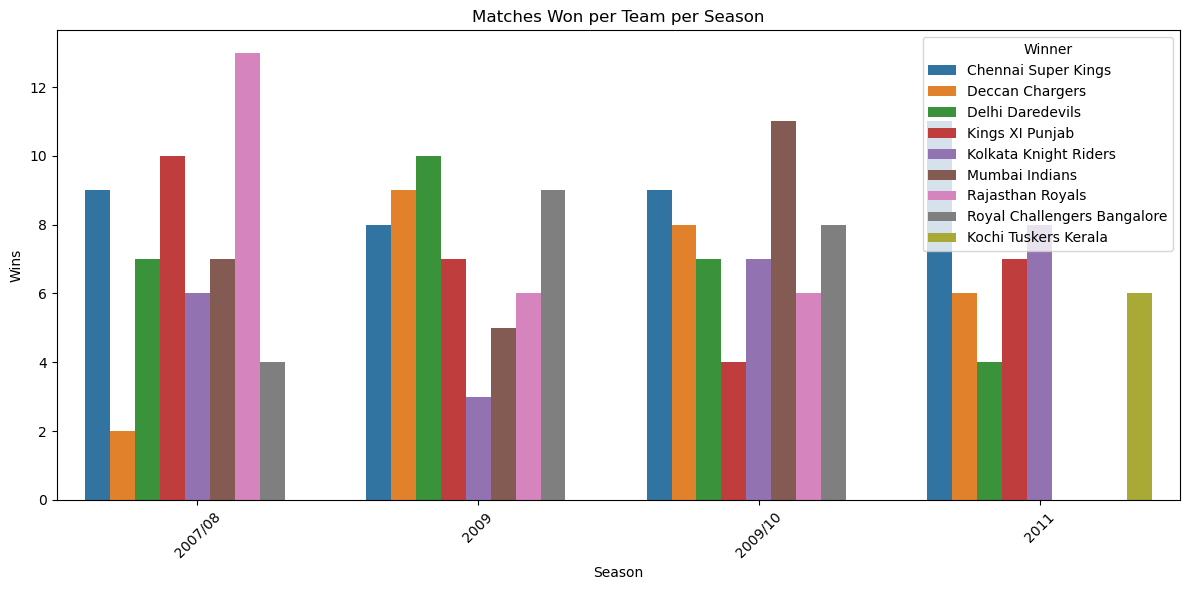

In [78]:
plt.figure(figsize=(12,6))
sns.barplot(data=grouped_df.head(30), x='Season', y='Wins', hue='Winner')
plt.title('Matches Won per Team per Season')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()